In [7]:
import importlib.util
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [17]:
REPO = Path.cwd()
while not (REPO / "data" / "processed").exists() and REPO != REPO.parent:
    REPO = REPO.parent
PANEL = REPO / "data" / "processed" / "ski_price_panel_cleaned.csv"
FIGDIR = REPO / "figures"
FIGDIR.mkdir(exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight",
    "font.size": 10, "axes.titlesize": 11, "axes.labelsize": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#8a8a85", "axes.labelcolor": "#0b0b0b",
    "text.color": "#0b0b0b", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": "#e4e3df", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
    "savefig.edgecolor": "white",
})
INK = "#52514e"
print(REPO)

C:\Users\Adam\OneDrive\HSLU\2026\CIP_HS26_208


In [9]:
spec = importlib.util.spec_from_file_location(
    "research_questions", REPO / "src" / "analysis" / "research_questions.py")
rq = importlib.util.module_from_spec(spec)
spec.loader.exec_module(rq)

df = rq.load(PANEL)
print(f"{len(df)} rows, {df.series_id.nunique()} series, {df.snapshot_date.nunique()} snapshots")

4602 rows, 777 series, 6 snapshots


In [10]:
exposure_tbl = rq.rq1(df)


RQ1: Holiday premium
OLS: holiday_exposure coef = 0.0925  ->  9.7% (exposure from 0 to 1), R2 = 0.748
Bootstrap over whole series (500 reps): coef 95% CI [0.0753, 0.1095]  ->  7.8% to 11.6%

Mean price by holiday exposure (none = 0, low = up to 0.33, high = above 0.33):
holiday_exposure   none    low   high  high_vs_none_%
resort                                               
Chäserrugg        48.21  51.88  54.07            12.2
Laax              67.79  78.54  81.06            19.6
Lauchernalp       70.67  70.67  70.67             0.0
Nendaz-Veysonnaz  73.70  78.41  78.32             6.3
Sörenberg         64.00  64.00  64.00             0.0
Titlis            56.68  59.04  59.78             5.5

Robustness (clustered SE, % price difference for the holiday variable):
  baseline, clustered SE                   9.7%  [7.8, 11.6]  n = 4602
  + month fixed effects                   10.6%  [8.2, 13.0]  n = 4602
  without the 2 flat-price resorts        14.1%  [11.7, 16.6]  n = 3270
  without

In [11]:
rq.rq2(df)


RQ2: Price drivers

Mean price by month:
        mean    std  count
month                     
1      65.44  10.24   1116
2      70.09  11.38   1008
3      65.38  10.35   1104
4      61.80  10.11    444
5      51.50   0.00      6
11     53.10   4.23    156
12     65.28  10.99    768

Mean price, weekend vs weekday:
             mean    std  count
is_weekend                     
False       65.04  10.98   3204
True        66.97  10.99   1398

Resort mean price and attributes:
                  mean_price  piste_km  n_lifts  base_altitude_m  top_altitude_m  vertical_drop_m
resort                                                                                           
Chäserrugg             50.92        50       12              900            2262             1362
Laax                   74.38       176       29             1100            3018             1918
Lauchernalp            70.67        40        6             1403            3100             1697
Nendaz-Veysonnaz       76.54 

In [12]:
lead_tbl = rq.rq3(df)

RQ3: Dynamic repricing
Valid pairs: 3825   changed: 331 (8.7%)   up: 331   down: 0
Mean absolute % change per event: 2.32%  (min 0.79, max 10.57)
Series with at least one change: 264 / 777 (34.0%)

By resort:
                  valid_pairs  changed_pairs  pct_changed
resort                                                   
Chäserrugg                575              9          1.6
Laax                      650             26          4.0
Lauchernalp               605            121         20.0
Nendaz-Veysonnaz          640              0          0.0
Sörenberg                 505              0          0.0
Titlis                    850            175         20.6

By lead time (days until the ski date):
       valid_pairs  changed_pairs  pct_changed
lead                                          
0-7             12             12        100.0
8-14            21             21        100.0
15-30           59             33         55.9
31-60          450             68         15.1
60+ 

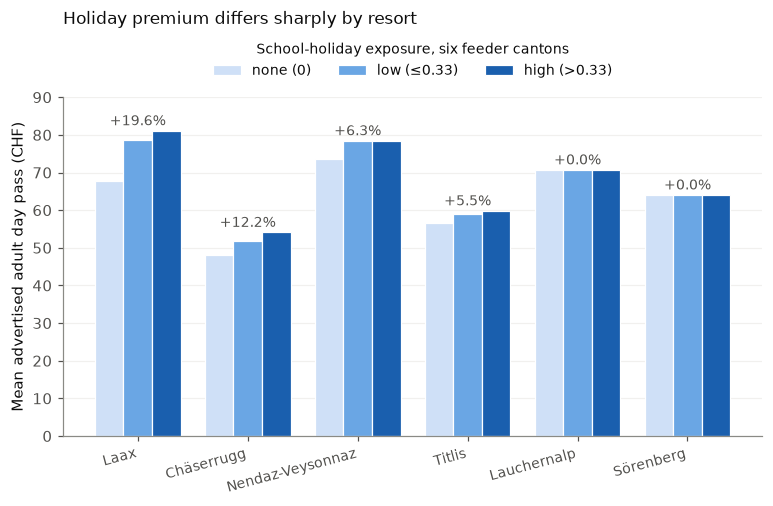

In [24]:
RAMP = ["#cfe0f7", "#6aa6e4", "#1a5fae"]   # sequential: more exposure = darker
LABELS = ["none (0)", "low (≤0.33)", "high (>0.33)"]
BANDS = rq.EXPOSURE_LABELS

m = exposure_tbl.rename(columns={"high_vs_none_%": "premium"}).sort_values("premium", ascending=False)

x, w = np.arange(len(m)), 0.26
fig, ax = plt.subplots(figsize=(8.2, 4.0))
for i, b in enumerate(BANDS):
    ax.bar(x + (i - 1) * w, m[b], w, label=LABELS[i],
           color=RAMP[i], edgecolor="white", linewidth=0.8)
for xi, (_, r) in zip(x, m.iterrows()):
    ax.annotate(f"{r['premium']:+.1f}%", (xi, max(r[BANDS]) + 1.5),
                ha="center", fontsize=9, color=INK)

ax.set_xticks(x); ax.set_xticklabels(m.index, fontsize=9, rotation=15, ha="right")
ax.set_ylabel("Mean advertised adult day pass (CHF)")
ax.set_ylim(0, 90)
ax.legend(title="School-holiday exposure, six feeder cantons",
          frameon=False, ncol=3, loc="lower center", bbox_to_anchor=(0.5, 1.02),
          fontsize=9, title_fontsize=9)
ax.set_title("Holiday premium differs sharply by resort", loc="left", pad=48)
fig.savefig(FIGDIR / "RQ1_holiday_premium_by_resort.png")
plt.show()

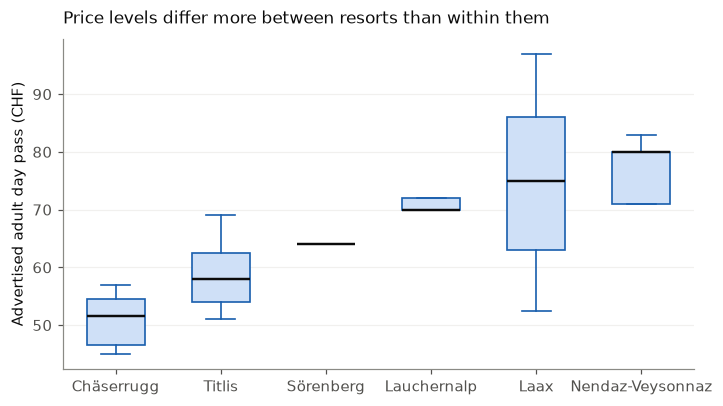

In [27]:
order = df.groupby("resort")["price_chf"].median().sort_values().index
data = [df.loc[df.resort == r, "price_chf"].values for r in order]

fig, ax = plt.subplots(figsize=(7.4, 3.9))
bp = ax.boxplot(data, patch_artist=True, widths=0.55,
                medianprops=dict(color="#0b0b0b", linewidth=1.6),
                flierprops=dict(marker="o", markersize=3.5,
                                markerfacecolor="#8a8a85", markeredgecolor="none", alpha=0.5))
for p in bp["boxes"]:
    p.set(facecolor="#cfe0f7", edgecolor="#1a5fae", linewidth=1.1)
for k in ("whiskers", "caps"):
    for p in bp[k]:
        p.set(color="#1a5fae", linewidth=1.1)

ax.set_xticklabels(order)
ax.set_ylabel("Advertised adult day pass (CHF)")
ax.set_title("Price levels differ more between resorts than within them", loc="left", pad=10)
fig.savefig(FIGDIR / "RQ2_price_distribution_by_resort.png")
plt.show()

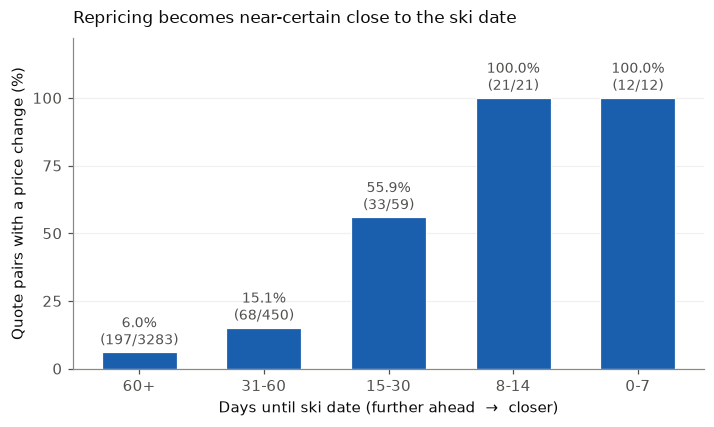

In [26]:
g = lead_tbl.reindex(rq.LEAD_LABELS[::-1]).rename(
        columns={"valid_pairs": "n", "changed_pairs": "changed", "pct_changed": "pct"})

fig, ax = plt.subplots(figsize=(7.4, 3.9))
ax.bar(range(len(g)), g["pct"], 0.6, color="#1a5fae", edgecolor="white", linewidth=0.8)
for i, r in enumerate(g.itertuples()):
    ax.annotate(f"{r.pct:.1f}%\n({r.changed}/{r.n})", (i, r.pct + 3),
                ha="center", fontsize=9, color=INK)

ax.set_xticks(range(len(g))); ax.set_xticklabels(g.index)
ax.set_xlabel("Days until ski date (further ahead  →  closer)")
ax.set_ylabel("Quote pairs with a price change (%)")
ax.set_ylim(0, 122); ax.set_yticks([0, 25, 50, 75, 100])
ax.set_title("Repricing becomes near-certain close to the ski date", loc="left", pad=10)
fig.savefig(FIGDIR / "RQ3_repricing_by_lead_time.png")
plt.show()